# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Bonus by Tung Thien: State space size:__ $|S|=n^n$

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

* __Bonus by Tung Thien: Neighborhood:__ The collection of all new neighboring states that can be reached from the current state by performing exactly one legal move. 

* __Bonus by Tung Thien: Size of neighbors per state:__ $|N(s)|=n(n-1)$

| Size | State Space | Neighbors per state |
|---|---:|---:|
| n = 4 | 256 | 12 |
| n = 8 | 16.777.216 | 56 |

## Helper functions

__Bonus by Tung Thien__: The three function (`random_board()`, `conflicts()`, `show_board()`) work smoothly, for now it does not have any error:

* __`random_board(n)`:__ Generate random board. `n`: Number of queens on the board.

* __`conflicts(board)`:__ Counting the number of queens attacking each other on the current state.

* __`show_board(board)`:__ Show the chess board using Matplotlib.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors

from pathlib import Path
from datetime import datetime
from pprint import pprint
import json

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

def save_log_result(
    result,
    algorithm="SA",
    log_dir="logs",
    image_dir="img/task_5_SA",
    show_full_history=False,
):
    """
    Hiển thị, lưu CSV và vẽ biểu đồ kết quả của thuật toán.

    result cần có:
        board_size
        best_board
        best_conflicts
        iterations
        history
        runtime_ms
        seed

    history nên là list các dictionary:
        {
            "iteration": ...,
            "conflicts": ...,
            "best_conflicts": ...,
            "temperature": ...,
            "accepted": ...
        }
    """

    required_keys = {
        "board_size",
        "best_board",
        "best_conflicts",
        "iterations",
        "history",
        "runtime_ms",
        "seed",
    }

    missing_keys = required_keys - result.keys()

    if missing_keys:
        raise ValueError(
            f"result đang thiếu các trường: {sorted(missing_keys)}"
        )

    board_size = result["board_size"]

    if not isinstance(board_size, int) or board_size <= 0:
        raise ValueError("board_size phải là một số nguyên dương.")

    if len(result["best_board"]) != board_size:
        raise ValueError(
            "board_size không khớp với số quân hậu trong best_board."
        )

    # Tạo thư mục nếu chưa tồn tại
    log_dir = Path(log_dir)
    image_dir = Path(image_dir)

    log_dir.mkdir(parents=True, exist_ok=True)
    image_dir.mkdir(parents=True, exist_ok=True)

    timestamp = datetime.now().astimezone()
    timestamp_text = timestamp.isoformat(timespec="seconds")
    file_timestamp = timestamp.strftime("%Y%m%d_%H%M%S_%f")
    run_id = f"{algorithm}_n{board_size}_{file_timestamp}"

    # Chuẩn hóa history thành DataFrame
    history = result["history"]

    if isinstance(history, pd.DataFrame):
        history_df = history.copy()
    else:
        history = list(history)

        if history and isinstance(history[0], dict):
            history_df = pd.DataFrame(history)
        else:
            # Cho phép history đơn giản dạng: [6, 5, 7, 3, 0]
            history_df = pd.DataFrame({"conflicts": history})

    # Nếu history rỗng, vẫn lưu được kết quả cuối
    if history_df.empty:
        history_df = pd.DataFrame(
            {
                "iteration": [result["iterations"]],
                "conflicts": [result["best_conflicts"]],
                "best_conflicts": [result["best_conflicts"]],
            }
        )

    if "iteration" not in history_df.columns:
        history_df.insert(0, "iteration", range(len(history_df)))

    if "conflicts" not in history_df.columns:
        raise ValueError(
            "Mỗi phần tử của history cần có trường 'conflicts'."
        )

    history_df["conflicts"] = pd.to_numeric(
        history_df["conflicts"],
        errors="coerce",
    )

    # Nếu chưa lưu best_conflicts ở từng iteration,
    # tự tính nghiệm tốt nhất tính đến thời điểm đó
    if "best_conflicts" not in history_df.columns:
        history_df["best_conflicts"] = history_df["conflicts"].cummin()

    if "temperature" not in history_df.columns:
        history_df["temperature"] = pd.NA

    if "accepted" not in history_df.columns:
        history_df["accepted"] = pd.NA

    # Thông tin nhận diện từng lần chạy
    history_df["run_id"] = run_id
    history_df["timestamp"] = timestamp_text
    history_df["algorithm"] = algorithm
    history_df["board_size"] = board_size
    history_df["runtime_ms"] = result["runtime_ms"]
    history_df["seed"] = result["seed"]

    # Chỉ lưu best_board tại dòng cuối để CSV bớt lặp dữ liệu
    history_df["best_board"] = ""
    history_df["is_final"] = False

    last_index = history_df.index[-1]
    history_df.loc[last_index, "best_board"] = json.dumps(
        result["best_board"],
        ensure_ascii=False,
        default=str,
    )
    history_df.loc[last_index, "is_final"] = True

    column_order = [
        "run_id",
        "timestamp",
        "algorithm",
        "board_size",
        "iteration",
        "conflicts",
        "best_conflicts",
        "temperature",
        "accepted",
        "is_final",
        "runtime_ms",
        "seed",
        "best_board",
    ]

    history_df = history_df.reindex(columns=column_order)

    # Tách log theo thuật toán và kích thước bàn cờ để tránh trộn n=4 với n=8
    csv_path = log_dir / f"{algorithm}_n{board_size}.csv"

    history_df.to_csv(
        csv_path,
        mode="a",
        header=not csv_path.exists(),
        index=False,
    )

    # Vẽ diễn biến conflicts
    figure, conflict_axis = plt.subplots(figsize=(10, 5))

    conflict_axis.plot(
        history_df["iteration"],
        history_df["conflicts"],
        label="Current conflicts",
        color="tab:blue",
        alpha=0.7,
    )

    conflict_axis.plot(
        history_df["iteration"],
        history_df["best_conflicts"],
        label="Best conflicts",
        color="tab:green",
        linewidth=2,
    )

    conflict_axis.set_xlabel("Iteration")
    conflict_axis.set_ylabel("Number of conflicts")
    conflict_axis.grid(alpha=0.25)

    # Vẽ temperature trên trục Y thứ hai nếu có dữ liệu
    temperature = pd.to_numeric(
        history_df["temperature"],
        errors="coerce",
    )

    axes = [conflict_axis]

    if temperature.notna().any():
        temperature_axis = conflict_axis.twinx()

        temperature_axis.plot(
            history_df["iteration"],
            temperature,
            label="Temperature",
            color="tab:red",
            linestyle="--",
            alpha=0.65,
        )

        temperature_axis.set_ylabel("Temperature")
        axes.append(temperature_axis)

    lines = []
    labels = []

    for axis in axes:
        axis_lines, axis_labels = axis.get_legend_handles_labels()
        lines.extend(axis_lines)
        labels.extend(axis_labels)

    conflict_axis.legend(lines, labels, loc="upper right")
    conflict_axis.set_title(
        f"{algorithm} (n={board_size}): conflicts over iterations "
        f"(best = {result['best_conflicts']})"
    )

    figure.tight_layout()

    image_path = image_dir / f"{run_id}.png"
    figure.savefig(image_path, dpi=150, bbox_inches="tight")

    plt.show()
    plt.close(figure)

    # In kết quả dạng dictionary
    printable_result = {
        "board_size": board_size,
        "best_board": result["best_board"],
        "best_conflicts": result["best_conflicts"],
        "iterations": result["iterations"],
        "history": (
            result["history"]
            if show_full_history
            else f"{len(history_df)} records"
        ),
        "runtime_ms": result["runtime_ms"],
        "seed": result["seed"],
    }

    pprint(printable_result, sort_dicts=False)

    print(f"\nCSV: {csv_path}")
    print(f"Biểu đồ: {image_path}")

    return history_df

## Create a board

Board with 4 conflicts.


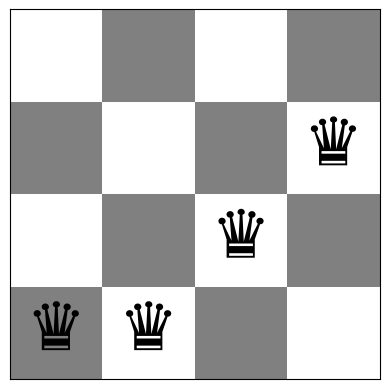

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


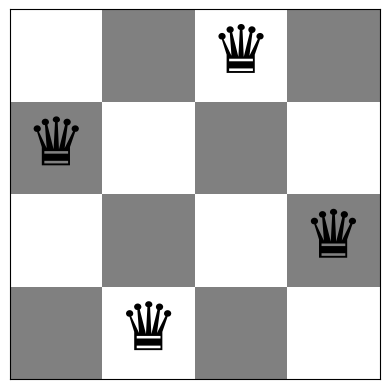

In [4]:
board = [1,3,0,2]
show_board(board)

Board with 8 conflicts.


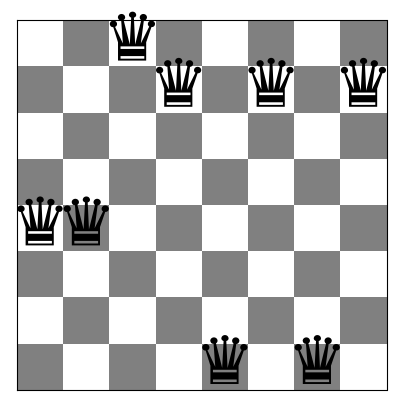

Queens (left to right) are at rows: [4 4 0 1 7 1 7 1]
Number of conflicts: 8


In [5]:
board = random_board(8)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [6]:
# Code and description go here

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [7]:
# Code and description go here

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [8]:
# Code and description go here

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [9]:
# Code and description go here

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [ ]:
from math import exp
from random import random, randint
from annealing_schedules import temperature_linear
import time
import pandas as pd

def simulated_annealing(n, board):
    def generating_neighboring_board(n, board):
        col = randint(0, n-1)
        neighboring_board = board.copy()
        while neighboring_board[col] == board[col]:
            neighboring_board[col] = randint(0, n-1)
        return neighboring_board

    history = []

    # Initial
    current_conflicts = conflicts(board)        # Checking how many pairs of queen are attacking each other
    best_board = board.copy()                   # Best board that has the least conflicts
    best_conflicts = current_conflicts
    temperature_initial = 0.4
    temperature = temperature_initial
    start_timer = time.perf_counter()
    max_iterations = 1000
    accepted = False
    seed = 1234

    history.append(
        {
            "iteration": 0,
            "conflicts": current_conflicts,
            "best_conflicts": best_conflicts,
            "temperature": temperature,
            "accepted": None,
        }
    )

    for iteration in range(1, max_iterations + 1):
        if best_conflicts == 0:
            break

        neighboring_board = generating_neighboring_board(n, board)
        neighboring_conflicts = conflicts(neighboring_board)
        
        delta = neighboring_conflicts - current_conflicts
        p = exp(-delta/temperature)
        random_num = random()

        if delta <= 0 or p > random_num:                # Nếu accepted thì cập nhật board/current_conflicts
            accepted = True
            board = neighboring_board.copy()
            current_conflicts = neighboring_conflicts

            if current_conflicts < best_conflicts:      # Nếu tìm thấy nghiệm tốt hơn thì cập nhật best_board
                best_board = board.copy()
                best_conflicts = current_conflicts

        history.append(                                 # Ghi history dù accepted là True hay False
            {
                "iteration": iteration,
                "conflicts": current_conflicts,
                "best_conflicts": best_conflicts,
                "temperature": temperature,
                "accepted": accepted,
            }
        )

        accepted = False
        end_timer = time.perf_counter()
        temperature = temperature_linear(iteration, temperature, eta=0.01)      # Giảm temperature

    # Dừng timer
    end_timer = time.perf_counter()
    runtime_ms = (end_timer - start_timer)*1000

    result = {
        "board_size": n,
        "best_board": best_board.tolist(),
        "best_conflicts": best_conflicts,
        "iterations": iteration,
        "history": history,
        "runtime_ms": runtime_ms,
        "seed": seed,
    }

    save_log_result(result, algorithm="SA")

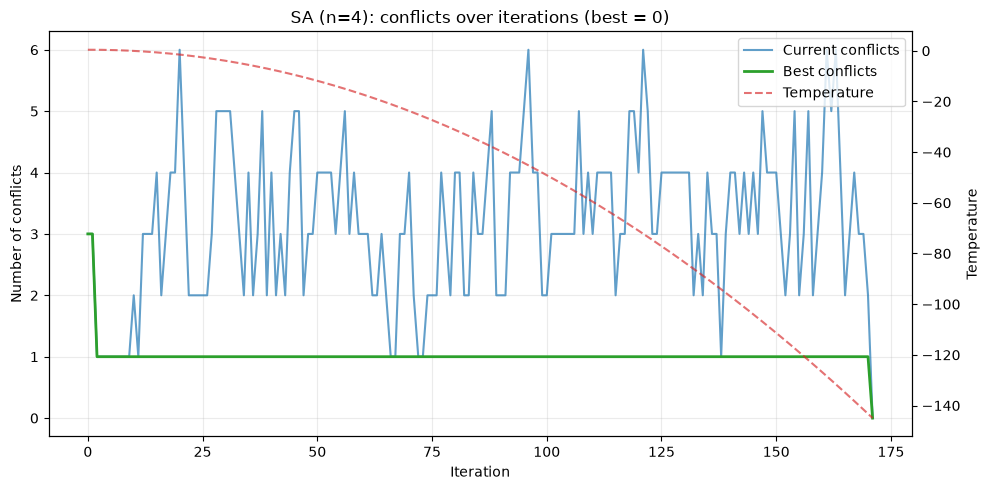

{'board_size': 4,
 'best_board': [1, 3, 0, 2],
 'best_conflicts': 0,
 'iterations': 172,
 'history': '172 records',
 'runtime_ms': 2.700176992220804,
 'seed': 1234}

CSV: logs/SA_n4.csv
Biểu đồ: img/task_5_SA/SA_n4_20261013_013243_924110.png


In [18]:
board_n4 = random_board(4)
simulated_annealing(4, board_n4)

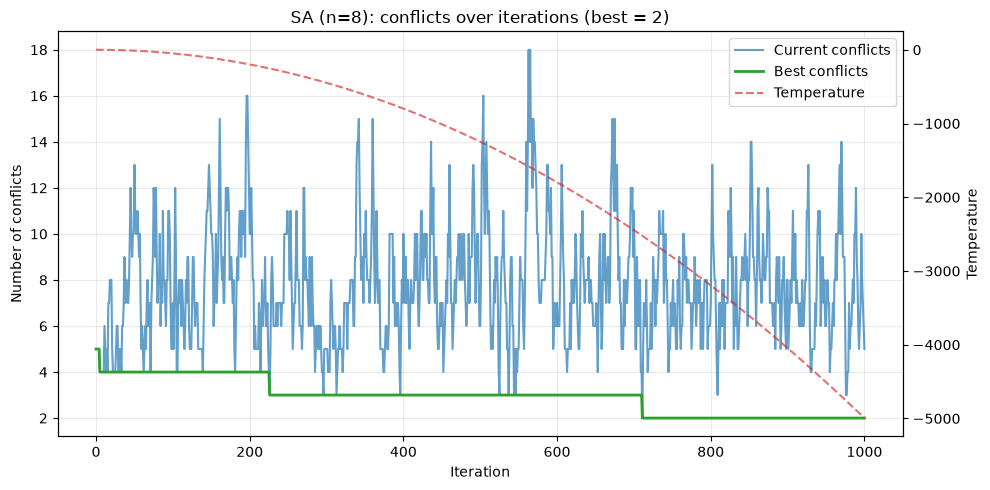

{'board_size': 8,
 'best_board': [2, 4, 7, 1, 4, 0, 5, 3],
 'best_conflicts': 2,
 'iterations': 1000,
 'history': '1001 records',
 'runtime_ms': 9.673171996837482,
 'seed': 1234}

CSV: logs/SA_n8.csv
Biểu đồ: img/task_5_SA/SA_n8_20261013_013251_135063.png


In [19]:
board_n8 = random_board(8)
simulated_annealing(8, board_n8)

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [13]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [14]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [15]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [16]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [17]:
# Code and description go here